In [ ]:
import operator
import os
import re
from typing import Annotated, List, Literal

import wikipedia
from ddgs import DDGS
from dotenv import load_dotenv
from IPython.display import Image, display
from pydantic import BaseModel, Field

from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_core.messages import AIMessage, AnyMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_groq import ChatGroq
from langchain_huggingface import ChatHuggingFace, HuggingFaceEmbeddings, HuggingFaceEndpoint
from langchain_text_splitters import RecursiveCharacterTextSplitter

from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Send

load_dotenv()  

True

In [59]:
endpoint = HuggingFaceEndpoint(repo_id="Qwen/Qwen3-32B", task="text-generation", max_new_tokens=4096)
llm = ChatHuggingFace(llm=endpoint)

llm2 = ChatGroq(model="openai/gpt-oss-120b")

In [60]:
pdfs = [
    "project1/1706.03762v7.pdf",   # Attention Is All You Need (Transformer)
    "project1/2005.11401v4.pdf",   # Retrieval-Augmented Generation (RAG)
    "project1/2210.03629v3.pdf",   # ReAct
    "project1/2310.11511v1.pdf",   # Self-RAG
    "project1/2401.15884v3.pdf",   # Corrective RAG (CRAG)
]

documents= []
for pdf in pdfs:
    doc = PyPDFLoader(pdf).load()
    documents.extend(doc)
    print(f"{pdf}: {len(doc)} pages")
print(f"Total pages: {len(documents)}")


project1\1706.03762v7.pdf: 15 pages
project1\2005.11401v4.pdf: 19 pages
project1\2210.03629v3.pdf: 33 pages
project1\2310.11511v1.pdf: 30 pages
project1\2401.15884v3.pdf: 16 pages
Total pages: 113


In [61]:
embeddings = HuggingFaceEmbeddings()
splitter = RecursiveCharacterTextSplitter(chunk_size =1000,chunk_overlap=150)
chunks = splitter.split_documents(documents)
vs = Chroma.from_documents(chunks,embeddings).as_retriever()
print(f"{len(chunks)} chunks indexed")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 497.61it/s]


489 chunks indexed


### TOOLS

In [62]:
#tool 1paper search from research papers
@tool
def serach_paper_tool(query:str) ->str:
    """Search a vector store of 5 AI research papers: 'Attention Is All You Need' (Transformer),
        'Retrieval-Augmented Generation (RAG)', 'ReAct', 'Self-RAG', and 'Corrective RAG (CRAG)'.
        Use it for questions about transformers, attention, retrieval-augmented generation,
        or reasoning-and-acting agents.
        Input: a specific search query in plain English (e.g. 'why is attention scaled by sqrt(d_k)').
        Returns: the most relevant passages, each with its paper and page number."""
    results = vs.invoke(query)
    return "\n\n".join(
            f"[{i}] {os.path.basename(d.metadata.get('source', ''))}, page {d.metadata.get('page_label', '?')}\n{d.page_content}"
            for i, d in enumerate(results, start=1)
        )

In [63]:
print(serach_paper_tool.invoke("why is attention scaled by sqrt(d_k)"))

[1] 1706.03762v7.pdf, page 4
extremely small gradients 4. To counteract this effect, we scale the dot products by 1√dk
.
3.2.2 Multi-Head Attention
Instead of performing a single attention function withdmodel-dimensional keys, values and queries,
we found it beneficial to linearly project the queries, keys and valuesh times with different, learned
linear projections todk,dk anddv dimensions, respectively. On each of these projected versions of
queries, keys and values we then perform the attention function in parallel, yieldingdv-dimensional
4To illustrate why the dot products get large, assume that the components of q and k are independent random
variables with mean 0 and variance 1. Then their dot product, q · k = Pdk
i=1 qiki, has mean 0 and variance dk.
4

[2] 1706.03762v7.pdf, page 4
extremely small gradients 4. To counteract this effect, we scale the dot products by 1√dk
.
3.2.2 Multi-Head Attention
Instead of performing a single attention function withdmodel-dimensional keys, va

In [64]:
# tool number 2 wiki
wikipedia.set_user_agent("agentic-ai-revision/1.0 (student project)")
wikipedia_wrapper = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=500)
@tool
def wiki_search(query:str)->str:
    """Search Wikipedia for general knowledge: people, places, organizations, historical events,
        and definitions of concepts.
        Use it for questions that are NOT covered by the 5 research papers in the vector store,
        or to get general background on a topic (e.g. 'who is Geoffrey Hinton', 'what is BERT').
        Do NOT use it for detailed questions about the Transformer, RAG, ReAct, Self-RAG,
        or CRAG papers; use paper_search_tool for those.
        Input: a short search term or question in plain English (e.g. 'Cristiano Ronaldo').
        Returns: short summaries of the top matching Wikipedia pages."""
    try:
        results = wikipedia_wrapper.load(query)
    except Exception as e:
        return f"Wikipedia search failed: {e}"
    return "\n\n".join(
            f"[{i}] {d.metadata.get('title', '')} ({d.metadata.get('source', '')})\n{d.page_content}"
            for i, d in enumerate(results, start=1)
        ) or "No Wikipedia results."


In [65]:
print(wiki_search.invoke("who is cristiano ronaldo?"))

[1] Messi–Ronaldo rivalry (https://en.wikipedia.org/wiki/Messi%E2%80%93Ronaldo_rivalry)
The Messi–Ronaldo rivalry, or Ronaldo–Messi rivalry, is a sporting rivalry in football propelled by the media and fans that involves Argentine footballer Lionel Messi and Portuguese footballer Cristiano Ronaldo, mainly for being contemporaries and due to their similar records and sporting successes. They spent nine seasons in the prime of their careers facing off regularly while playing for rival clubs Barcelona and Real Madrid.
Together, they have achieved various historical milestones, coming 

[2] Cristiano Ronaldo (https://en.wikipedia.org/wiki/Cristiano_Ronaldo)
Cristiano Ronaldo dos Santos Aveiro (born 5 February 1985) is a Portuguese professional footballer who plays as a forward for and captains the Saudi Pro League club Al-Nassr. Nicknamed CR7, he has won numerous individual accolades throughout his career, including five Ballons d'Or, a record three UEFA Men's Player of the Year Awards, an

In [66]:
### tool 3 duck duck search
@tool
def duck_duck_search(query:str)->str:
    """Search the web with DuckDuckGo for recent, current, or very specific information.
    Use it for news, recent events, latest releases or versions, current facts that may have
    changed (e.g. 'latest GPT model', 'which AI models use transformers today'),
    or anything not found by the other tools.
    Do NOT use it for questions about the 5 research papers (use paper_search_tool)
    or for stable general background like biographies and definitions (use wiki_search_tool).
    Input: a concise search query in plain English, as you would type into a search engine.
    Returns: the top web results, each with a title, URL, and short snippet."""
    try:
        results = DDGS().text(query, max_results=5)
    except Exception as e:
        return f"Search failed: {e}"
    return "\n\n".join(
            f"[{i}] {r['title']} ({r['href']})\n{r['body']}"
            for i, r in enumerate(results, start=1)
        ) or "No web results."

In [67]:
print(duck_duck_search.invoke("who is travisscott"))

[1] Travis Scott - Wikipedia (https://en.wikipedia.org/wiki/Travis_Scott)
Jacques Bermon Webster II (born April 30, 1991), known professionally as Travis Scott, is an American rapper, singer-songwriter, and record producer. Scott has had five number-one hits on the U.S. Billboard Hot 100 chart, along with a total of over one hundred charting songs.

[2] Travis Scott | Biography, Music & News | Billboard (https://www.billboard.com/artist/travis-scott/)
Known for his raucous performance style and free-for-all concerts, Travis Scott is a Houston-born rapper who stands at a height of 5’10”. His birthday is April 30, 1991.

[3] Travis Scott Biography, Age, Children, Height, Net Worth (https://www.nextbiography.com/travis-scott/)
May 26, 2026 · Travis Scott is an American rapper, singer, songwriter, and record producer whose real name is Jacques Bermon Webster II. He built his reputation through boundary-pushing albums, sold-out world tours, and some of the most iconic brand collaborations i

In [68]:
tools = [serach_paper_tool,duck_duck_search,wiki_search]
llm_with_tools = llm.bind_tools(tools)

### States !!!!!

In [69]:
""" as if here we are having multiple research agents that is going
 to be accessed so that each will need to contain an isolated state byy himself 
 and a structured oytput that they will return with"""

' as if here we are having multiple research agents that is going\n to be accessed so that each will need to contain an isolated state byy himself \n and a structured oytput that they will return with'

In [70]:
class ResearcherState(BaseModel):
    sub_question :str
    messages : Annotated[list[AnyMessage],add_messages]=[]
    evidence : Annotated[list[dict],operator.add]= []
    rounds: int = 0
class ReseaacherOutput(BaseModel):
    evidence : Annotated[list[dict],operator.add]=[]
    
class MainState(BaseModel):
    questions: Annotated[List[AnyMessage], add_messages]
    sub_questions: Annotated[List[str], operator.add] = []     # planner's + reflector's follow-ups
    evidence: Annotated[List[dict], operator.add] = []         # merged from all researchers
    answers: Annotated[List[AnyMessage], add_messages] = []    # every draft; answers[-1] is the latest
    decision: str = ""                                         # reflector: accept / revise / research_more
    feedback: str = ""                                         # reflector -> synthesizer (revise)
    follow_ups: List[str] = []                                 # reflector -> new researchers (research_more)
    reflections: int = 0     


In [ ]:
### Planner agent
class Planner(BaseModel):
    sub_questions: list[str] = Field(
        description="The user's question broken into 1-4 short, self-contained sub-questions, "
                    "each answerable with a single search. Use just 1 if the question is simple."
    ) 
PLANNER_PROMPT = SystemMessage(content="""You are the Planner in a research team.
Break the user's question into sub-questions. Each sub-question goes to a separate researcher who works in parallel and does NOT see the original question.
Rules:
- Write 1 to 4 sub-questions. Use just 1 if the question is simple.
- Make each one self-contained: repeat names and terms instead of writing "it", "this" or "they".
- Make each one cover a different part of the question, with no overlap.
- Together, they must cover the whole question.
- Do not answer them.""")

planner_llm = llm2.with_structured_output(Planner)
def planner_node(state: MainState) -> dict:
    plan = planner_llm.invoke([PLANNER_PROMPT, state.questions[-1]])
    return {"sub_questions": plan.sub_questions}     


In [72]:
planner_node(MainState(questions=[HumanMessage(
    "What is the transformer architecture, and which well-known AI models are built on it today?"
)]))

{'sub_questions': ['What is the transformer architecture?',
  'Which well-known AI models are built on the transformer architecture today?']}

In [73]:
### Researcher agent contains also the grader to the content
RESEARCHER_PROMPT = """You are a Researcher in a multi-agent research team. Your job is to gather evidence for ONE sub-question, not to write the final answer.

## The team
- Planner: split the user's question into sub-questions. Other researchers are working on the other ones in parallel.
- Researcher (you): finds evidence for your sub-question using your tools.
- Grader: reviews each tool result before you see it. It removes irrelevant results and adds a note starting with "GRADER:" that says what is still missing.
- Synthesizer: receives the evidence from all researchers and writes the final answer.
- Reflector: reviews the final answer and may send follow-up sub-questions to new researchers.

## Your sub-question
{sub_question}

## Your tools
1. paper_search_tool: searches 5 AI research papers (Transformer, RAG, ReAct, Self-RAG, CRAG). Use it for technical details from the papers.
2. wiki_search_tool: searches Wikipedia. Use it for general background, definitions, people, and history.
3. duck_duck_search: searches the web. Use it for recent or current information, and for anything the other tools couldn't find.

## How to work
1. Pick the tool that fits your sub-question best. Use more than one if the sub-question has several parts.
2. Read the GRADER notes. If one says "nothing relevant" or that something is still missing, rewrite the query with different keywords or switch to another tool.
3. Use specific search queries. Do not answer from your own memory.
4. Stop calling tools once you have enough evidence, or once you have tried every suitable tool.

## When you are done
Do not write the final answer. Reply with one line: "covered", or "not found: <what you tried>"."""

def researcher_agent_node(state:ResearcherState)->dict:
    sys_mssge = SystemMessage(content=RESEARCHER_PROMPT.format(sub_question =state.sub_question ))
    response = llm_with_tools.invoke([sys_mssge, HumanMessage(state.sub_question)] + state.messages)
    return {"messages": [response]}


### Grader
class GraderOutput(BaseModel):
    relevant: list[int] = Field(description="Numbers of the results that help answer the question")
    still_missing: str = Field(description="One sentence on what is still missing, or empty if nothing")

GRADER_PROMPT = SystemMessage(content="""You are a relevance grader for a research assistant.
You will receive a question and a numbered list of search results.
1. Return the numbers of the results that directly help answer the question, even partially. Ignore results that are only loosely related.
2. In one sentence, say what information is still missing. Leave it empty if nothing is missing.
If no result is relevant, return an empty list. Do not answer the question yourself.""")
grader_llm = llm2.with_structured_output(GraderOutput)

def research_grader_node(state: ResearcherState) -> dict:
    question = state.sub_question

    # this round's tool results = the ToolMessages at the end of the conversation
    tool_msgs = []
    for m in reversed(state.messages):
        if not isinstance(m, ToolMessage):
            break
        tool_msgs.append(m)
    cleaned, evidence = [], []
    for m in tool_msgs:
        results = re.split(r"\n\n(?=\[\d+\])", m.content.strip())
        numbered = "\n\n".join(f"Result {i}:\n{r}" for i, r in enumerate(results, start=1))
        out = grader_llm.invoke([GRADER_PROMPT, HumanMessage(f"Question: {question}\n\n{numbered}")])
        kept = [results[i - 1] for i in out.relevant if 1 <= i <= len(results)]
        evidence += [{"sub_question": question, "tool": m.name, "text": r} for r in kept]
        if kept:
            note = f"GRADER: kept {len(kept)} of {len(results)}. Still missing: {out.still_missing or 'nothing'}"
        else:
            note = "GRADER: nothing relevant. Rewrite the query with different keywords or try another tool."
        cleaned.append(m.model_copy(update={"content": "\n\n".join(kept + [note])}))

    return {"messages": cleaned, "evidence": evidence, "rounds": state.rounds + 1}





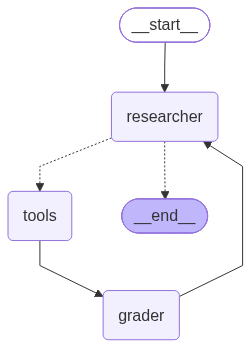

In [74]:
MAX_ROUNDS = 3   
def researcher_route(state: ResearcherState):
    if state.rounds >= MAX_ROUNDS:   
        return END
    return tools_condition(state)  

graph = StateGraph(ResearcherState , output_schema= ReseaacherOutput)


graph.add_node("researcher",researcher_agent_node)
graph.add_node("grader",research_grader_node)
graph.add_node("tools", ToolNode(tools))

graph.add_edge(START,"researcher")
graph.add_conditional_edges("researcher",researcher_route,{"tools":"tools", END:END })
graph.add_edge("tools","grader")
graph.add_edge("grader", "researcher")

graph_researcher= graph.compile()
graph_researcher



In [75]:
# test ONE researcher on its own -> returns only {"evidence": [...]}
r = graph_researcher.invoke({"sub_question": "What is the Transformer architecture?"})
for e in r["evidence"]:
    print(f"[{e['tool']}] {e['text'][:200]}\n")

[serach_paper_tool] [1] 1706.03762v7.pdf, page 3
Figure 1: The Transformer - model architecture.
The Transformer follows this overall architecture using stacked self-attention and point-wise, fully
connected layers for b

[serach_paper_tool] [2] 1706.03762v7.pdf, page 3
Figure 1: The Transformer - model architecture.
The Transformer follows this overall architecture using stacked self-attention and point-wise, fully
connected layers for b

[serach_paper_tool] [1] 1706.03762v7.pdf, page 3
Figure 1: The Transformer - model architecture.
The Transformer follows this overall architecture using stacked self-attention and point-wise, fully
connected layers for b

[serach_paper_tool] [2] 1706.03762v7.pdf, page 3
Figure 1: The Transformer - model architecture.
The Transformer follows this overall architecture using stacked self-attention and point-wise, fully
connected layers for b

[serach_paper_tool] [3] 1706.03762v7.pdf, page 5
output values. These are concatenated and once again projected,

In [ ]:
### sendf to multiple researchers instead of only 1

def send_researchers(state:MainState):
    return [Send("graph_researcher",{"sub_question":question}) for question in state.sub_questions]

In [77]:
def unique_sources(evidence: list[dict]) -> list[dict]:
    """Drop duplicate results (two researchers can find the same passage)."""
    seen, sources = set(), []
    for e in evidence:
        if e["text"] not in seen:
            seen.add(e["text"])
            sources.append(e)
    return sources


def strip_number(text: str) -> str:
    """'[3] paper.pdf, page 2\n...' -> 'paper.pdf, page 2\n...'"""
    return re.sub(r"^\[\d+\]\s*", "", text)


def format_sources(sources: list[dict]) -> str:
    """One global numbering [1] ... [n], tagged with the sub-question each source answers."""
    return "\n\n".join(
        f"[{n}] (for: {s['sub_question']})\n{strip_number(s['text'])}"
        for n, s in enumerate(sources, start=1)
    )


def build_references(answer: str, sources: list[dict]) -> str:
    """References list for the [n] numbers the answer actually cites."""
    cited = sorted({int(n) for n in re.findall(r"\[(\d+)\]", answer) if 1 <= int(n) <= len(sources)})
    if not cited:
        return ""
    lines = [f"[{n}] {strip_number(sources[n - 1]['text']).splitlines()[0]}" for n in cited]
    return "\n\n## References\n" + "\n".join(lines)

In [78]:
SYNTHESIZER_PROMPT = SystemMessage(content="""You are the Synthesizer in a research team. Researchers have gathered numbered sources. Write the final answer to the user's question using ONLY these sources.

Rules:
- Base every statement on the sources. Do not use outside knowledge.
- Cite every fact inline with its source number, like [1] or [2][5]. Only use numbers from the list.
- Cover every part of the question. If the sources don't answer a part, say so honestly.
- If sources disagree, say so and explain the difference.
- Answer the question directly first, then add supporting details. Be concise.
- Do NOT write a references list; it is added automatically.""")


def synthesizer_node(state: MainState) -> dict:
    sources = unique_sources(state.evidence)
    request = f"Question: {state.questions[-1].content}\n\nSources:\n{format_sources(sources)}"

    if state.feedback:   # revise loop: show the previous draft and what to fix
        request += (f"\n\nYour previous draft:\n{state.answers[-1].content}"
                    f"\n\nThe Reflector asked for these fixes:\n{state.feedback}"
                    "\n\nWrite the corrected answer.")

    answer = llm2.invoke([SYNTHESIZER_PROMPT, HumanMessage(request)]).content
    return {"answers": [AIMessage(answer + build_references(answer, sources))]}

In [79]:
class Reflection(BaseModel):
    decision: Literal["accept", "revise", "research_more"] = Field(
        description="accept = supported and complete; revise = fix the writing; research_more = information is missing")
    feedback: str = Field(
        description="For 'revise': which claims are unsupported or wrongly cited, and how to fix them. Empty otherwise.")
    follow_up_questions: list[str] = Field(
        description="For 'research_more': 1-3 self-contained sub-questions covering only what is missing. Empty otherwise.")


REFLECTOR_PROMPT = SystemMessage(content="""You are the Reflector in a research team. You review a draft answer against the numbered sources it was written from.

Check, in this order:
1. Support: every fact must have a citation [n], and source n must actually say it. Facts with no citation, or with a citation that doesn't back them, are unsupported.
2. Coverage: the answer must cover every part of the user's question.

Then decide:
- accept: every fact is supported and every part of the question is covered. Minor style issues are fine.
- revise: the sources contain what is needed, but the answer has unsupported claims, wrong citations, or leaves out something the sources do say. Give specific feedback.
- research_more: the sources do NOT contain information needed for part of the question. Write 1-3 self-contained follow-up sub-questions for only the missing parts (repeat names instead of "it" or "this").

Be strict about made-up facts and lenient about style.""")

reflector_llm = llm2.with_structured_output(Reflection)


def reflector_node(state: MainState) -> dict:
    sources = unique_sources(state.evidence)
    review = reflector_llm.invoke([REFLECTOR_PROMPT, HumanMessage(
        f"Question: {state.questions[-1].content}\n\n"
        f"Sources:\n{format_sources(sources)}\n\n"
        f"Draft answer:\n{state.answers[-1].content}"
    )])

    follow_ups = review.follow_up_questions if review.decision == "research_more" else []
    return {
        "decision": review.decision,
        "feedback": review.feedback if review.decision == "revise" else "",
        "follow_ups": follow_ups,
        "sub_questions": follow_ups,       
        "reflections": state.reflections + 1,
    }

In [90]:
loop_max = 3
def router_after_reflection(state:MainState):
    if state.decision == "accept" or state.reflections >=loop_max:
        return END
    if state.decision =="revise":
        return "synthesizer"
    if state.follow_ups:
        return[Send("graph_researcher", {"sub_question": question}) for question in state.follow_ups]
    return END

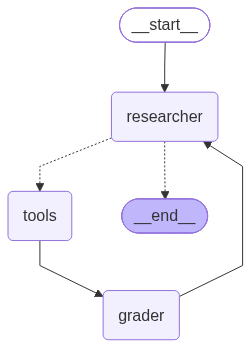

In [81]:
graph_researcher

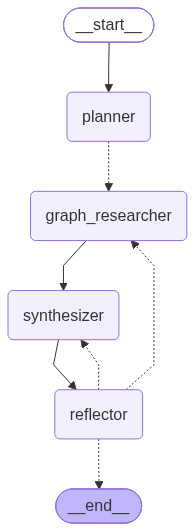

In [92]:
### Full graph

full_graph = StateGraph(MainState)
full_graph.add_node("planner",planner_node)
full_graph.add_node("graph_researcher", graph_researcher)
full_graph.add_node("synthesizer",synthesizer_node)
full_graph.add_node("reflector",reflector_node)

full_graph.set_entry_point("planner")
full_graph.add_conditional_edges("planner",send_researchers ,["graph_researcher"])
full_graph.add_edge("graph_researcher","synthesizer")
full_graph.add_edge("synthesizer","reflector")
full_graph.add_conditional_edges("reflector", router_after_reflection, ["synthesizer", "graph_researcher", END])



grapher = full_graph.compile()
grapher

In [93]:
question = "What is the transformer architecture, and which well-known AI models are built on it today?"
result = grapher.invoke({"questions": [HumanMessage(question)]})



print("Sub-questions:")
for q in result["sub_questions"]:
    n = sum(e["sub_question"] == q for e in result["evidence"])
    print(f"  - {q}  ({n} evidence items)")
print(f"\nReviews: |  last decision: {result['decision']}\n")

result["answers"][-1].pretty_print()

Sub-questions:
  - What are the key components and principles of the transformer architecture in deep learning?  (8 evidence items)
  - Which well-known AI models currently in use are built on the transformer architecture?  (3 evidence items)

Reviews: |  last decision: accept

================================== Ai Message ==================================

The transformer is a deep‑learning architecture built from stacked encoder and decoder blocks that rely on multi‑head self‑attention and position‑wise feed‑forward networks, with residual connections and layer‑normalization applied around each sub‑layer.  

* **Encoder** – Six identical layers, each containing (i) a multi‑head self‑attention sub‑layer and (ii) a fully‑connected feed‑forward sub‑layer; both are wrapped by a residual connection followed by LayerNorm [1][2].  
* **Decoder** – Six identical layers that add a third sub‑layer: multi‑head attention over the encoder’s output. The decoder’s self‑attention is masked so that 